# Loading data

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from random import randint

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

device = "cuda" if torch.cuda.is_available() else "cpu"

def normalize(input_array):
    min_val = np.min(input_array)
    max_val = np.max(input_array)
    
    return (input_array - min_val) / (max_val - min_val)

def standardize(input_array):
    return (input_array - np.mean(input_array)) / np.std(input_array)
def mimic_standardize(input_array, mimic_mean, mimic_std):
    return (input_array - mimic_mean) / mimic_std

# data import

data_in = np.genfromtxt("fourth_dataset/db4_combined_input_6.csv", delimiter=",", dtype=np.float32)
data_out = np.genfromtxt("fourth_dataset/db4_combined_output_6x.csv", delimiter=",", dtype=np.float32)
nb_data = data_in.shape[0]
  
def stack4_tensor(input_np_array):
    output_np = np.reshape(input_np_array, (input_np_array.shape[0], input_np_array.shape[1] // 4, 4))
    return torch.tensor(output_np, dtype=torch.float32)
def stack6_tensor(input_np_array):
    output_np = np.reshape(input_np_array, (input_np_array.shape[0], input_np_array.shape[1] // 6, 6))
    return torch.tensor(output_np, dtype=torch.float32)

data_in_torch = stack4_tensor(data_in)
data_out_torch = stack6_tensor(data_out)

Normalizing accordingly to training data

In [7]:
nb_data = data_in_torch.size(0)
train_size = int(0.90*nb_data)
val_size = int(0.00*nb_data)
test_size = int(0.10*nb_data)

input_data = mimic_standardize(data_in_torch, torch.tensor([ 2.1357e+00,  2.0267e-03, -3.4298e-04, -4.7241e-05]), torch.tensor([2.8753, 0.9143, 0.8546, 0.8566]))
output_data = mimic_standardize(data_out_torch, torch.tensor([-1.5773e-01, -2.2508e-01, -5.8805e+01, -9.1914e-03,  2.9042e-01,
         1.1632e+00]), torch.tensor([ 19.1642,  19.9494, 113.0530,  20.7793,  20.4650,  59.5704]))

# Testing via Torch model

In [8]:
class ModelNN(nn.Module):
    def __init__(
        self,
        input_size: int = 1,
        output_size: int = 1,
        rnn_type: str = "RNN",  # "RNN", "LSTM", "GRU"
        hidden_size: int = 16,
        num_layers: int = 1,
        dropout: float = 0.0
    ):
        super().__init__()
        
        # Select and initialize the RNN type
        if rnn_type.upper() == "LSTM":
            self.rnn = nn.LSTM(
                input_size=input_size,
                hidden_size=hidden_size,
                num_layers=num_layers,
                dropout=dropout if num_layers > 1 else 0.0,
                batch_first=True
            )
        elif rnn_type.upper() == "GRU":
            self.rnn = nn.GRU(
                input_size=input_size,
                hidden_size=hidden_size,
                num_layers=num_layers,
                dropout=dropout if num_layers > 1 else 0.0,
                batch_first=True
            )
        elif rnn_type.upper() == "RNN":
            self.rnn = nn.RNN(
                input_size=input_size,
                hidden_size=hidden_size,
                num_layers=num_layers,
                nonlinearity='tanh',
                dropout=dropout if num_layers > 1 else 0.0,
                batch_first=True
            )
        
        self.head = nn.Linear(hidden_size, output_size)
        
    def forward(self, x, h=None):
        out, h_new = self.rnn(x, h)
        return self.head(out), h_new
    
hidden_layer_size = 128

model = ModelNN(4, 6, "LSTM", hidden_layer_size, 2)
model.load_state_dict(torch.load("rnn_model_thrust_pos.pt", weights_only=True))


<All keys matched successfully>

# Computing max errors of the model against test data

In [16]:
mean_distances = []
max_distances = []

distances = []

idx_measure = 0

for idx in range(train_size+val_size, nb_data):
    full_sequence = input_data[idx].unsqueeze(0)
    h0 = torch.zeros((2, 1, hidden_layer_size))
    c0 = torch.zeros((2, 1, hidden_layer_size))
    h = (h0, c0)

    outputs_list = []
    for t in range(full_sequence.size(1)):
        x_step = full_sequence[:, t:t+1, :]
        
        out, h = model(x_step, h)
        outputs_list.append(out)
        
    outputs_cat = torch.cat(outputs_list, axis=1)
    
    distances.append(np.abs(outputs_cat[0].detach().numpy() - output_data[idx].detach().numpy()))
    
    mean_distances.append(torch.mean(torch.abs(outputs_cat[0][:, idx_measure].detach() - output_data[idx][:, idx_measure].detach())))
    max_distances.append(torch.max(torch.abs(outputs_cat[0][:, idx_measure].detach() - output_data[idx][:, idx_measure].detach())))

distances = np.stack(distances, axis=0)
mean_distances = np.array(mean_distances)
max_distances = np.array(max_distances)

distances.shape, mean_distances.shape, max_distances.shape

((625, 161, 6), (625,), (625,))

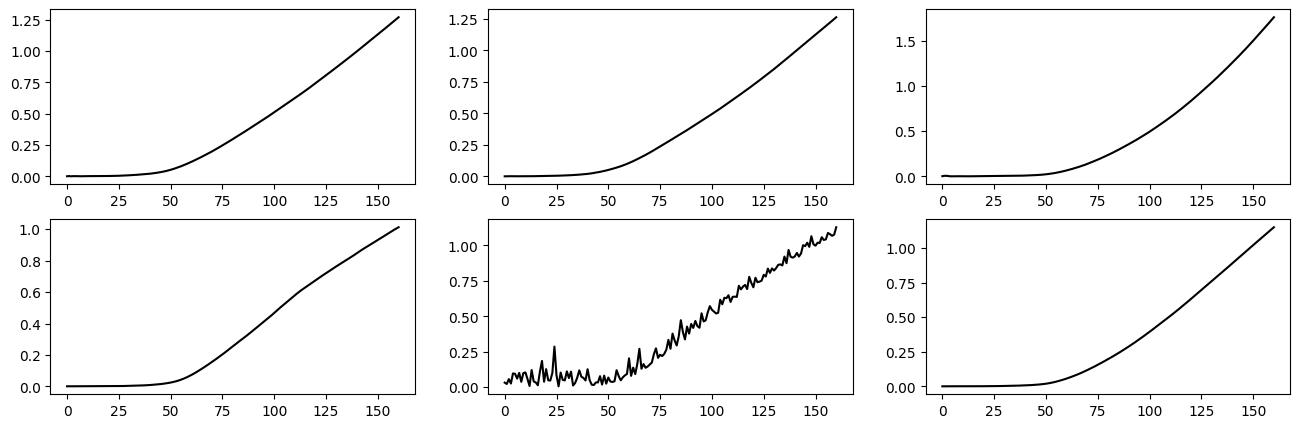

In [17]:
average_on_test = np.mean(distances, axis=0)
fig, axes = plt.subplots(2, 3)
fig.set_figheight(5)
fig.set_figwidth(16)
for i in range(6):
    axes[i//3, i%3].plot(average_on_test[:, i], c="black")

(array([1., 1., 1., 0., 0., 1., 0., 3., 0., 1., 1., 1., 0., 1., 0., 1., 0.,
        3., 1., 1., 1., 0., 2., 1., 0., 1., 3., 0., 2., 1., 1., 1., 1., 0.,
        1., 3., 1., 0., 1., 0., 0., 0., 0., 0., 0., 1., 1., 1., 2., 1., 2.,
        2., 1., 1., 2., 0., 2., 2., 2., 1., 1., 1., 1., 2., 2., 3., 2., 2.,
        4., 1., 3., 5., 5., 2., 1., 3., 1., 5., 5., 2., 1., 3., 4., 5., 3.,
        3., 2., 2., 0., 4., 3., 0., 0., 1., 0., 0., 1., 1., 1., 1.]),
 array([0.26072937, 0.28230625, 0.30388314, 0.32546005, 0.34703693,
        0.36861381, 0.39019072, 0.4117676 , 0.43334448, 0.45492136,
        0.47649825, 0.49807516, 0.51965201, 0.54122889, 0.56280583,
        0.58438271, 0.60595959, 0.62753648, 0.64911336, 0.6706903 ,
        0.69226718, 0.71384406, 0.73542094, 0.75699782, 0.77857471,
        0.80015159, 0.82172847, 0.84330535, 0.86488229, 0.88645917,
        0.90803605, 0.92961293, 0.95118982, 0.9727667 , 0.99434358,
        1.0159204 , 1.03749728, 1.05907428, 1.08065116, 1.10222805,
      

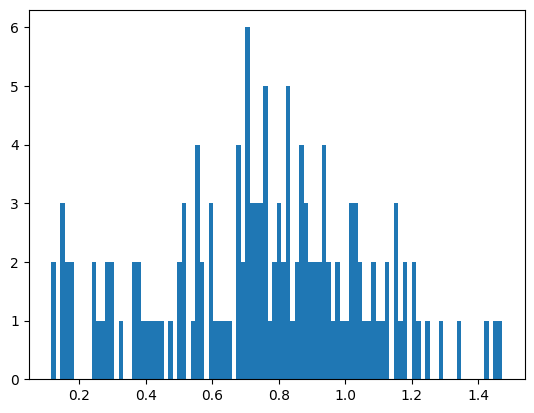

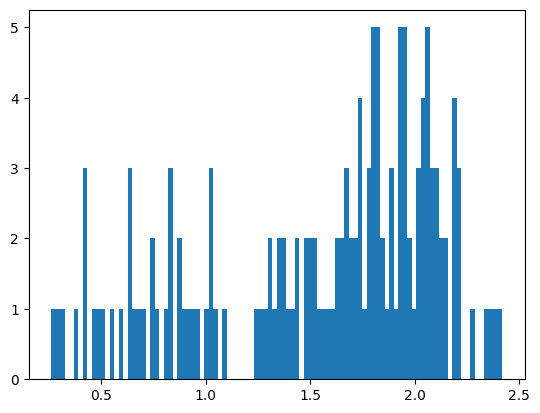

In [115]:
plt.figure()
plt.hist(mean_distances, bins=100)
plt.figure()
plt.hist(max_distances, bins=100)

In [141]:
for i in range(6):
    print(np.mean(distances[:, :, i]))

0.7527949
0.59739065
0.4186585
0.12544504
0.12132713
0.07531198


Comparing for a given sample

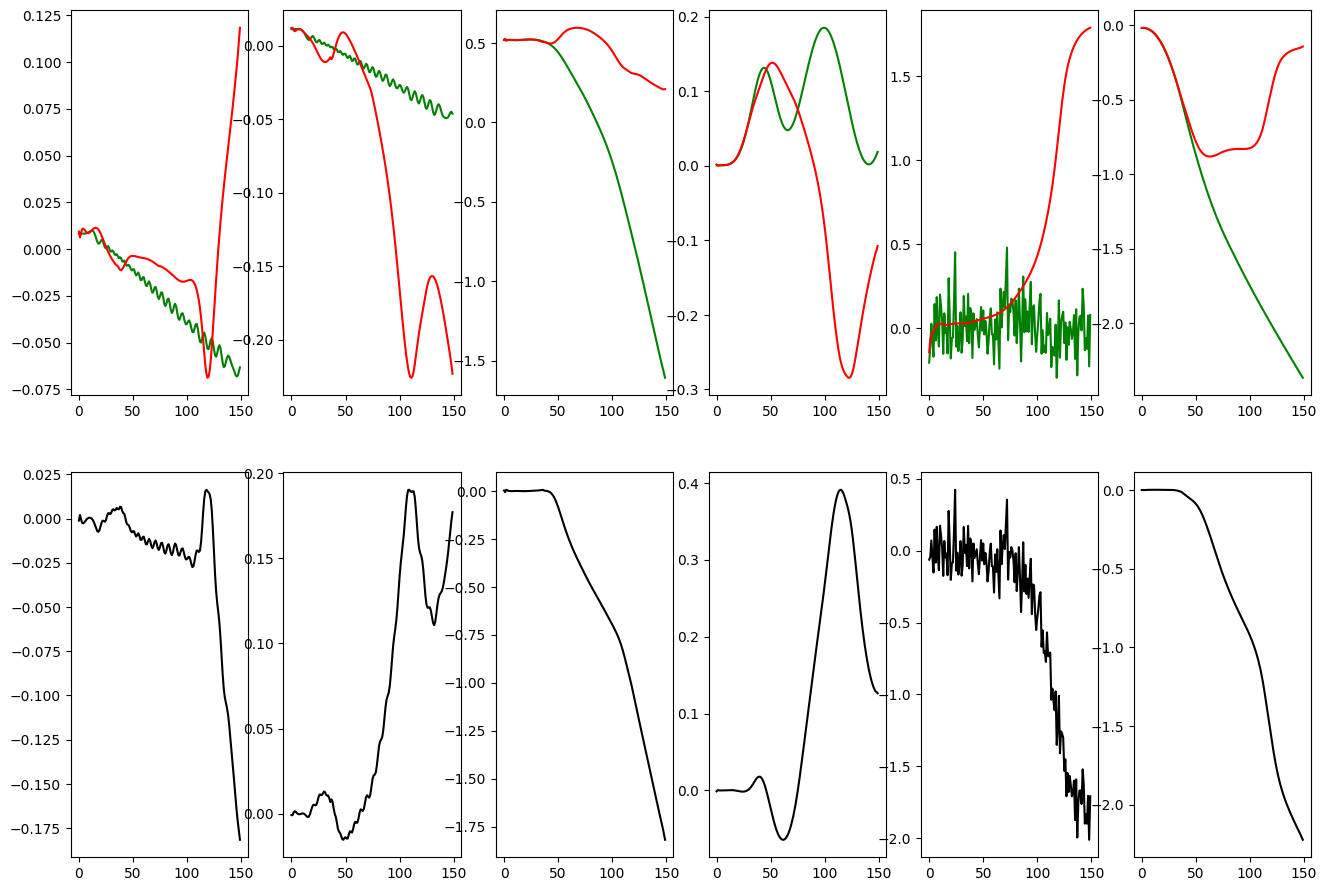

In [32]:
train_rand_idx = randint(0, train_size-1)
test_rand_idx = randint(train_size+val_size, nb_data-1)
idx = test_rand_idx
end_idx = 150

full_sequence = input_data[idx].unsqueeze(0)
h0 = torch.zeros((2, 1, hidden_layer_size))
c0 = torch.zeros((2, 1, hidden_layer_size))
h = (h0, c0)

outputs_list = []
for t in range(full_sequence.size(1)):
    x_step = full_sequence[:, t:t+1, :]
    
    out, h = model(x_step, h)
    outputs_list.append(out)
    
outputs_cat = torch.cat(outputs_list, axis=1)

fig, axes = plt.subplots(2, 6)
fig.set_figheight(11)
fig.set_figwidth(16)
plt.plot()
for i in range(6):
    axes[0, i].plot(output_data[idx][:end_idx, i].detach().numpy(), c="green")
    axes[0, i].plot(outputs_cat[0][:end_idx, i].detach().numpy(), c="red")
    axes[1, i].plot(output_data[idx][:end_idx, i].detach().numpy() - outputs_cat[0][:end_idx, i].detach().numpy(), c="black")

# ONNX version (not working yet)

In [3]:
import onnx
import onnxruntime

onnx_model = onnx.load("../rnn_model_all_outputs.onnx")
onnx.checker.check_model(onnx_model)

In [4]:
input_data.size()

torch.Size([1960, 161, 4])

In [ ]:
ort_session = onnxruntime.InferenceSession(
    "../rnn_model_all_outputs.onnx", providers=["CPUExecutionProvider"]
)

input_names = [inp.name for inp in ort_session.get_inputs()]
x_name = input_names[0]
h_name = input_names[1]

train_rand_idx = randint(0, train_size-1)
test_rand_idx = randint(train_size+val_size, nb_data-1)
idx = test_rand_idx

full_sequence = input_data[idx].reshape(1, -1, 4).numpy()

hidden_size = 32
h = np.zeros((1, 1, hidden_size), dtype=np.float32)

onnxruntime_outputs_list = []

for t in range(full_sequence.shape[1]):
    x_step = full_sequence[:, t:t+1, :]
    
    out, h = ort_session.run(
        None, 
        {x_name: x_step, h_name: h}
    )
    onnxruntime_outputs_list.append(out)

onnxruntime_outputs = np.concatenate(onnxruntime_outputs_list, axis=1)

plt.plot(input_data[idx].numpy(), c="blue", alpha=0.3)
plt.plot(output_data[idx].numpy(), c="green", alpha=0.5)
plt.plot(onnxruntime_outputs[0], c="red", alpha=0.7)

# plt.plot(output_data[idx] - onnxruntime_outputs[:, :][0][:, 0], c="blue")
plt.show()

InvalidArgument: [ONNXRuntimeError] : 2 : INVALID_ARGUMENT : Got invalid dimensions for input: x for the following indices
 index: 1 Got: 1 Expected: 5
 Please fix either the inputs/outputs or the model.